Панова Светлана 09.07.14п2
Практическая работа №5   09_10_2026

Загружаем библиотеки

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Загружаем датасет

In [ ]:
df = pd.read_csv('/content/titanic.csv')

Выводим первые 5 строк

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Выбор признаков и целевой переменной

In [ ]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

In [ ]:
data = df[features + [target]].copy()

Проверка пропущенных значений

In [ ]:
data.isnull().sum()

,0
Pclass,0
Age,177
Sex,0
Fare,0
SibSp,0
Parch,0
Survived,0


Убираем пропущенные значения

In [ ]:
data = data.dropna()

Преобразование признака Sex из текстового значения в числовое

In [ ]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

In [ ]:
data.info()


<class 'pandas.core.frame.DataFrame'>
Index: 714 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    714 non-null    int64  
 1   Age       714 non-null    float64
 2   Sex       714 non-null    int64  
 3   Fare      714 non-null    float64
 4   SibSp     714 non-null    int64  
 5   Parch     714 non-null    int64  
 6   Survived  714 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 44.6 KB


Расчет корреляционной матрицы

In [ ]:
corr_matrix = data.corr()

Округление до двух знаков

In [ ]:
corr_matrix_rounded = corr_matrix.round(2)

In [ ]:
corr_matrix_rounded

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
Pclass,1.00,-0.37,-0.16,-0.55,0.07,0.03,-0.36
Age,-0.37,1.00,-0.09,0.10,-0.31,-0.19,-0.08
Sex,-0.16,-0.09,1.00,0.18,0.10,0.25,0.54
Fare,-0.55,0.10,0.18,1.00,0.14,0.21,0.27
SibSp,0.07,-0.31,0.10,0.14,1.00,0.38,-0.02
Parch,0.03,-0.19,0.25,0.21,0.38,1.00,0.09
Survived,-0.36,-0.08,0.54,0.27,-0.02,0.09,1.00


Находим столбец Survived

In [ ]:
survived_corr = corr_matrix_rounded['Survived'].drop('Survived')

Определяем признак с наиболее сильной положительной корреляцией с Survived

In [ ]:
most_positive = survived_corr.idxmax()
most_positive_value = survived_corr.max()

In [ ]:
print(most_positive, ":", most_positive_value)

Sex : 0.54


Определяем признак с наиболее сильной отрицательной корреляцией с Survived

In [ ]:
most_negative = survived_corr.idxmin()
most_negative_value = survived_corr.min()

In [ ]:
print(most_negative, ":", most_negative_value)


Pclass : -0.36


In [ ]:
survived_corr.sort_values(ascending=False)

,Survived
Sex,0.54
Fare,0.27
Parch,0.09
SibSp,-0.02
Age,-0.08
Pclass,-0.36


Построение тепловой карты

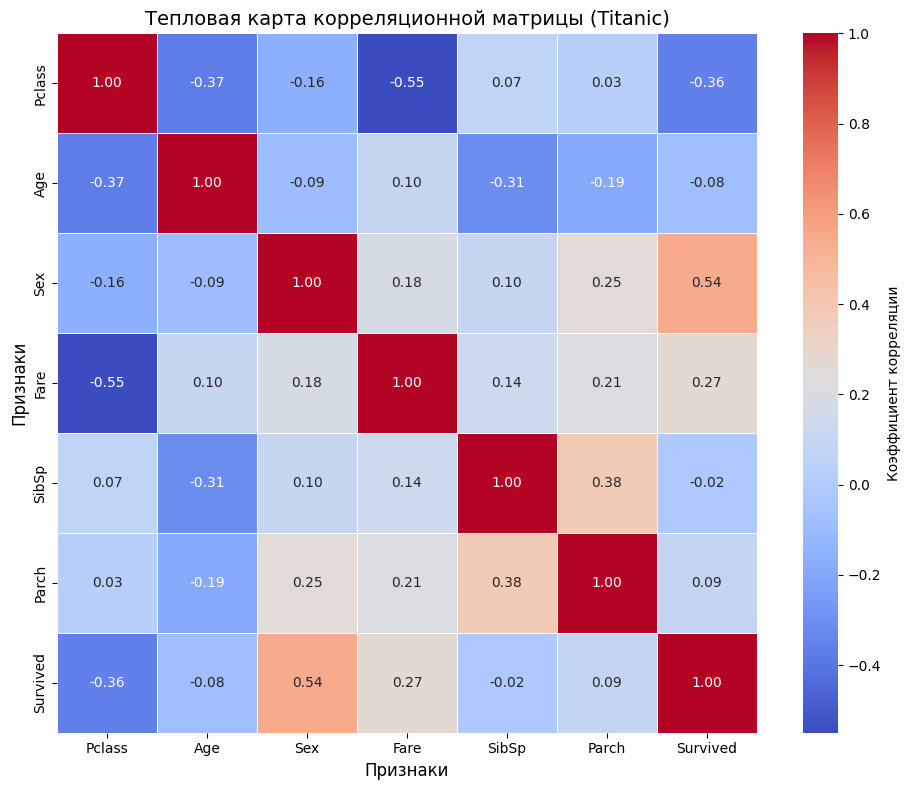

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix_rounded,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True,
    cbar_kws={'label': 'Коэффициент корреляции'}
)
plt.title('Тепловая карта корреляционной матрицы (Titanic)', fontsize=14)

plt.xlabel('Признаки', fontsize=12)
plt.ylabel('Признаки', fontsize=12)

plt.tight_layout()
plt.show()

1. sns.heatmap() — функция для построения тепловой карты.

---

2. Корреляционную матрицу (corr_matrix_rounded) — квадратную таблицу коэффициентов корреляции между всеми парами признаков.

---
3. annot=True — параметр, который добавляет числовые значения в каждую ячейку.

---
4. cmap — параметр цветовой карты (например, 'coolwarm', 'viridis', 'RdBu_r').

---
5. Через plt.figure(figsize=(ширина, высота)) перед вызовом sns.heatmap()




Какие признаки, по вашему мнению, могут быть наиболее полезны для предсказания Survived?

---
Наиболее полезные признаки для модели: Sex, Pclass, Fare. Именно они несут основную предсказательную информацию.


---
Sex самый сильный положительный предиктор

Положительная корреляция означает: женщины выживали значительно чаще мужчин


Pclass самый сильный отрицательный предиктор

Отрицательная корреляция: чем выше номер класса, тем меньше шансов выжить

Fare умеренная положительная связь

Дорогие билеты - выше класс - больше шансов выжить




Можно ли выбирать признаки только по корреляции?

---

Нет.
Корреляция ловит только линейную связь
Не видит взаимодействия признаков
Не учитывает нелинейности (возраст: дети и пожилые — по-разному)
